# Pipeline Prediksi Arah & Besaran Return Kurs USD/IDR (Title-Only: BERT vs DeBERTa & FinBERT vs DeBERTa Sentimen)

Notebook ini mengadopsi **seluruh pipeline pada `trial7.ipynb`** secara identik, dengan modifikasi fokus pada **input judul berita saja (`all_title`)** dan **perbandingan model berbasis DeBERTa**:
1. **Strict Anti-Leakage Split (70% Train / 15% Val / 15% Test)** secara kronologis di paling awal sebelum ekstraksi fitur, scaling, PCA/UMAP, BERTopic, threshold sentimen ekstrem, atau tuning.
2. **Perbandingan Embedding Judul Only (Frozen Layer)**:
   - **BERT-base (`bert-base-uncased`)** layer *freeze* pada judul berita (`max_length=48`).
   - **DeBERTa-v3-base (`microsoft/deberta-v3-base`)** layer *freeze* pada judul berita (`max_length=48`).
   - Reduksi dimensi dengan **PCA-8** (fit strictly di **Train**) + **Studi Ablasi Embedding** (`BERT Only` vs `DeBERTa Only` vs `BERT + DeBERTa`).
3. **Perbandingan Sentiment Analysis & Polaritas Kontinu (Frozen Layer)**:
   - **FinBERT (`ProsusAI/finbert`)** vs **DeBERTa Finance Sentiment (`nickmuchi/deberta-v3-base-finetuned-finance-text-classification`)**.
   - **Logika Kurs Indonesia (USD/IDR)**: berita internasional negatif $\rightarrow$ `kurs_pressure > 0` (Rupiah naik/melemah); positif $\rightarrow$ `kurs_pressure < 0` (Rupiah turun/menguat); berita netral mempertahankan kecenderungan kontinu (`P(neg) - P(pos)`, mis. `-0.1`).
   - **Studi Ablasi Sentimen**: Tanpa Sentimen vs FinBERT (Diskrit/Kontinu) vs DeBERTa Sentimen (Diskrit/Kontinu) vs Gabungan keduanya.
4. **BERTopic (`all-MiniLM-L6-v2` frozen, fit di Train saja)** + reduksi **PCA-5** dan **UMAP-2D**.
5. **Stage 1 Classifier Arah Return** (tuned on Val + **5-Fold OOF** di Train) $\rightarrow$ **Fitur Interaksi `Sentimen × Arah`** (Tinggi Q70 & Ekstrem Q90) $\rightarrow$ **14 Fitur Time-Series Kausal**.
6. **Perbandingan Arsitektur Neural (MLP, LSTM, Bi-LSTM)** + **Fine-Grained Hyperparameter Tuning** model terbaik + **Studi Ablasi Aditif & Leave-One-Group-Out (LOGO)**.

## 1. Setup Lingkungan & Seed Deterministik

In [1]:
# !pip install -q bertopic  # Aktifkan di Kaggle/Colab jika bertopic belum terpasang

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["USE_TF"] = "0"

import gc
import re
import copy
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from sentence_transformers import SentenceTransformer

from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed: int = SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
})
sns.set_style("whitegrid")

print(f"Device aktif : {DEVICE}")
print(f"PyTorch      : {torch.__version__}")

C:\Users\grace\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device aktif : cpu
PyTorch      : 2.13.0+cpu


## 2. Pemuatan Dataset & Split Kronologis di Awal (Zero Leakage)

Membaca `merged_data_clean.csv`, menghitung `rate_mid`, `log_ret`, dan target arah `y_dir` (`1 = Kurs Naik`, `0 = Kurs Turun`), lalu **langsung melakukan split kronologis `70% Train / 15% Val / 15% Test` di awal** sebelum ekstraksi fitur parametrik apa pun.

In [3]:
DATA_CANDIDATES = [
    Path("data/processed/merged_data_clean.csv"),
    Path("../data/processed/merged_data_clean.csv"),
    Path("/kaggle/input/datasets/graceee12/process-dataset/processed/merged_data_clean.csv")
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Tidak menemukan data/processed/merged_data_clean.csv!")

PROJECT_ROOT = DATA_PATH.parent.parent.parent
LONGFORMER_CACHE_PATH = PROJECT_ROOT / "data" / "cache_embeddings" / "longformer_daily_fulltext_1024.npz"

df = pd.read_csv(DATA_PATH)
date_col = "Tanggal_dt" if "Tanggal_dt" in df.columns else "tanggal"
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

if "rate_mid" not in df.columns:
    df["rate_mid"] = (df["Kurs Jual"] + df["Kurs Beli"]) / 2.0

df["log_ret"] = np.log(df["rate_mid"] / df["rate_mid"].shift(1))
df = df.dropna(subset=["log_ret"]).reset_index(drop=True)
df["y_dir"] = (df["log_ret"] > 0).astype(int)

def clean_text_keep_case(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["title_clean"] = df["all_title"].fillna("").apply(clean_text_keep_case)
df["fulltext_clean"] = df["all_full_text"].fillna("").apply(clean_text_keep_case)
df["norm_clean"] = df["all_normalized_text"].fillna("").apply(clean_text_keep_case)
df["has_news"] = (df["news_count"].fillna(0) > 0).astype(int)

# SPLIT KRONOLOGIS DI AWAL (70% Train / 15% Val / 15% Test)
n_total = len(df)
train_end_idx = int(n_total * 0.70)
val_end_idx = int(n_total * 0.85)

df["split"] = "test"
df.loc[:train_end_idx - 1, "split"] = "train"
df.loc[train_end_idx:val_end_idx - 1, "split"] = "val"

train_end_date = df.loc[train_end_idx - 1, date_col]
val_end_date = df.loc[val_end_idx - 1, date_col]

is_tr = (df["split"] == "train").values
is_va = (df["split"] == "val").values
is_te = (df["split"] == "test").values

print(f"Dataset: {n_total:,} hari perdagangan valid")
for sp, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    print(
        f"  {sp:5s}: {len(sub):4d} hari | {sub[date_col].min().date()} s/d {sub[date_col].max().date()} "
        f"| Naik={sub['y_dir'].mean()*100:.1f}% | Ada Berita={sub['has_news'].mean()*100:.1f}%"
    )

Dataset: 1,201 hari perdagangan valid
  Train:  840 hari | 2021-09-02 s/d 2025-02-18 | Naik=55.4% | Ada Berita=86.8%
  Val  :  180 hari | 2025-02-19 s/d 2025-11-21 | Naik=53.3% | Ada Berita=88.9%
  Test :  181 hari | 2025-11-24 s/d 2026-09-01 | Naik=57.5% | Ada Berita=98.3%


## 2. Embedding Judul Only (Frozen Layer): BERT-base vs DeBERTa-v3-base + PCA & Studi Ablasi

- Seluruh ekstraksi embedding hanya menggunakan kolom judul (`title_clean`) dengan bobot pre-trained yang **di-freeze** (`requires_grad=False`, `eval()`).
- Membandingkan **BERT-base** (`bert-base-uncased`) vs **DeBERTa-v3-base** (`microsoft/deberta-v3-base`).
- `StandardScaler` + `PCA(n_components=8)` di-fit **hanya pada Train set (`is_tr`)** lalu ditransformasikan ke Val dan Test.

In [4]:
CACHE_DIR = PROJECT_ROOT / "data" / "cache_embeddings"

def extract_daily_title_embeddings(model_name: str, unique_titles: list[str], title_lists, cache_file: Path, batch_size: int = 64, max_len: int = 48):
    if cache_file.exists():
        z = np.load(cache_file)
        if len(z["daily_emb"]) == len(title_lists):
            print(f"[CACHE] Memuat embedding judul dari {cache_file.name}: {z['daily_emb'].shape}")
            return z["daily_emb"].astype(np.float32)

    print(f"Memuat frozen model untuk embedding judul: {model_name} ...")
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModel.from_pretrained(model_name).to(DEVICE)
    if DEVICE == "cpu":
        mdl = mdl.float()
    mdl.eval()
    for p in mdl.parameters():
        p.requires_grad = False

    sorted_titles = sorted(unique_titles, key=len)
    title_emb_map = {}
    with torch.inference_mode():
        for i in range(0, len(sorted_titles), batch_size):
            batch_txt = sorted_titles[i : i + batch_size]
            enc = tok(batch_txt, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
            out = mdl(**enc).last_hidden_state
            mask = enc["attention_mask"].unsqueeze(-1).float()
            emb = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
            emb_np = emb.cpu().numpy()
            for t_str, vec in zip(batch_txt, emb_np):
                title_emb_map[t_str] = vec

    hidden_dim = next(iter(title_emb_map.values())).shape[0]
    daily_emb = np.zeros((len(title_lists), hidden_dim), dtype=np.float32)
    for row_idx, t_list in enumerate(title_lists):
        if t_list:
            daily_emb[row_idx] = np.mean([title_emb_map[t] for t in t_list], axis=0)

    del mdl, tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    try:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(cache_file, daily_emb=daily_emb)
    except Exception:
        pass
    return daily_emb


title_lists = [[p.strip() for p in s.split(" | ") if p.strip()] for s in df["title_clean"]]
unique_titles = sorted({t for sub in title_lists for t in sub}, key=len)
print(f"Total judul unik: {len(unique_titles):,} | Hari dengan berita: {int(df['has_news'].sum())}/{len(df)}")

# 2A. Frozen BERT-base Title Embedding
BERT_MODEL_NAME = "bert-base-uncased"
daily_bert_title = extract_daily_title_embeddings(
    BERT_MODEL_NAME, unique_titles, title_lists, CACHE_DIR / "bert_title_daily_768.npz", batch_size=64, max_len=48
)
print(f"BERT Title daily matrix: {daily_bert_title.shape}")

# 2B. Frozen DeBERTa-v3-base Title Embedding
DEBERTA_MODEL_NAME = "microsoft/deberta-v3-base"
daily_deberta_title = extract_daily_title_embeddings(
    DEBERTA_MODEL_NAME, unique_titles, title_lists, CACHE_DIR / "deberta_v3_title_daily_768.npz", batch_size=64, max_len=48
)
print(f"DeBERTa Title daily matrix: {daily_deberta_title.shape}")

# Reduksi dimensi PCA (fit ONLY on Train)
N_PCA_BERT = 8
sc_bert = StandardScaler().fit(daily_bert_title[is_tr])
pca_bert = PCA(n_components=N_PCA_BERT, random_state=SEED).fit(sc_bert.transform(daily_bert_title[is_tr]))
bert_pca_feats = pca_bert.transform(sc_bert.transform(daily_bert_title))
bert_pca_cols = [f"bert_pca_{i}" for i in range(N_PCA_BERT)]
for i, c in enumerate(bert_pca_cols):
    df[c] = bert_pca_feats[:, i].astype(np.float32)

N_PCA_DEB = 8
sc_deb = StandardScaler().fit(daily_deberta_title[is_tr])
pca_deb = PCA(n_components=N_PCA_DEB, random_state=SEED).fit(sc_deb.transform(daily_deberta_title[is_tr]))
deb_pca_feats = pca_deb.transform(sc_deb.transform(daily_deberta_title))
deberta_pca_cols = [f"deberta_pca_{i}" for i in range(N_PCA_DEB)]
for i, c in enumerate(deberta_pca_cols):
    df[c] = deb_pca_feats[:, i].astype(np.float32)

print(f"PCA Var Explained -> BERT-Title (8): {pca_bert.explained_variance_ratio_.sum():.3f} | DeBERTa-Title (8): {pca_deb.explained_variance_ratio_.sum():.3f}")

# Studi Ablasi Embedding Judul: BERT vs DeBERTa vs Gabungan
y_tr_dir = df.loc[is_tr, "y_dir"].values
y_va_dir = df.loc[is_va, "y_dir"].values
y_te_dir = df.loc[is_te, "y_dir"].values

def eval_dir_logreg(feat_cols: list[str], name: str):
    sc = StandardScaler().fit(df.loc[is_tr, feat_cols])
    clf = LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000, random_state=SEED)
    clf.fit(sc.transform(df.loc[is_tr, feat_cols]), y_tr_dir)
    p_va = clf.predict_proba(sc.transform(df.loc[is_va, feat_cols]))[:, 1]
    p_te = clf.predict_proba(sc.transform(df.loc[is_te, feat_cols]))[:, 1]
    return {
        "Skenario Embedding": name,
        "Dim": len(feat_cols),
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
        "Test BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_te >= 0.5).astype(int)) * 100, 2),
        "Test ROC-AUC": round(roc_auc_score(y_te_dir, p_te), 4),
    }

emb_ablation_df = pd.DataFrame([
    eval_dir_logreg(bert_pca_cols, "1. BERT Title Only (PCA-8)"),
    eval_dir_logreg(deberta_pca_cols, "2. DeBERTa Title Only (PCA-8)"),
    eval_dir_logreg(bert_pca_cols + deberta_pca_cols, "3. BERT + DeBERTa Title (PCA-16)"),
]).set_index("Skenario Embedding")
print("\n=== STUDI ABLASI EMBEDDING JUDUL: BERT vs DeBERTa ===")
display(emb_ablation_df)

Total judul unik: 4,138 | Hari dengan berita: 1067/1201
[CACHE] Memuat embedding judul dari bert_title_daily_768.npz: (1201, 768)
BERT Title daily matrix: (1201, 768)


[CACHE] Memuat embedding judul dari deberta_v3_title_daily_768.npz: (1201, 768)
DeBERTa Title daily matrix: (1201, 768)


PCA Var Explained -> BERT-Title (8): 0.452 | DeBERTa-Title (8): 0.490

=== STUDI ABLASI EMBEDDING JUDUL: BERT vs DeBERTa ===


,Dim,Val BalAcc (%),Val ROC-AUC,Test BalAcc (%),Test ROC-AUC
Skenario Embedding,,,,,
1. BERT Title Only (PCA-8),8,52.98,0.5050,54.20,0.5235
2. DeBERTa Title Only (PCA-8),8,59.15,0.5826,48.53,0.4810
3. BERT + DeBERTa Title (PCA-16),16,52.16,0.5218,53.84,0.5152


## 3. Analisis Sentimen & Polaritas Kontinu (Judul Only): FinBERT vs DeBERTa + Studi Ablasi Sentimen

Logika khusus prediksi kurs Indonesia (**USD/IDR**):
- Berita internasional **sentimen negatif** $\rightarrow$ `kurs_pressure > 0` $\rightarrow$ **Rupiah naik** (USD/IDR menguat).
- Berita internasional **sentimen positif** $\rightarrow$ `kurs_pressure < 0` $\rightarrow$ **Rupiah turun** (USD/IDR melemah).
- Berita **netral** tetap mempertahankan kecenderungan kontinu `kurs_pressure = P(negatif) - P(positif)` (misal `-0.10` = turun sedikit).

Kita bandingkan dua model sentimen finansial (frozen):
1. **FinBERT (`ProsusAI/finbert`)**
2. **DeBERTa-v3 Finance Sentiment (`nickmuchi/deberta-v3-base-finetuned-finance-text-classification`)** (`bearish`=negatif, `neutral`=netral, `bullish`=positif)

In [5]:
from transformers import AutoModelForSequenceClassification

def extract_daily_sentiment(model_name: str, unique_titles: list[str], title_lists, prefix: str, cache_file: Path, batch_size: int = 64, max_len: int = 64):
    loaded_ok = False
    if cache_file.exists():
        z = np.load(cache_file)
        if len(z["daily_pos"]) == len(title_lists):
            print(f"[CACHE] Memuat sentimen {prefix} dari {cache_file.name}: {len(z['daily_pos'])} hari")
            daily_pos = z["daily_pos"].astype(np.float32)
            daily_neg = z["daily_neg"].astype(np.float32)
            daily_neu = z["daily_neu"].astype(np.float32)
            loaded_ok = True

    if not loaded_ok:
        print(f"Memuat frozen sentiment model: {model_name} ...")
        tok = AutoTokenizer.from_pretrained(model_name)
        mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE)
        if DEVICE == "cpu":
            mdl = mdl.float()
        mdl.eval()
        for p in mdl.parameters():
            p.requires_grad = False

        id2lbl = {int(k): v.lower() for k, v in mdl.config.id2label.items()}
        print(f"  -> id2label ({prefix}): {id2lbl}")
        pos_idx = next(k for k, v in id2lbl.items() if ("pos" in v) or ("bull" in v))
        neg_idx = next(k for k, v in id2lbl.items() if ("neg" in v) or ("bear" in v))
        neu_idx = next(k for k, v in id2lbl.items() if "neu" in v)

        sorted_titles = sorted(unique_titles, key=len)
        sent_map = {}
        with torch.inference_mode():
            for i in range(0, len(sorted_titles), batch_size):
                batch_txt = sorted_titles[i : i + batch_size]
                enc = tok(batch_txt, padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEVICE)
                logits = mdl(**enc).logits
                probs = torch.softmax(logits, dim=-1).cpu().numpy()
                for t_str, pr in zip(batch_txt, probs):
                    sent_map[t_str] = (float(pr[pos_idx]), float(pr[neg_idx]), float(pr[neu_idx]))

        del mdl, tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        daily_pos = np.zeros(len(title_lists), dtype=np.float32)
        daily_neg = np.zeros(len(title_lists), dtype=np.float32)
        daily_neu = np.zeros(len(title_lists), dtype=np.float32)
        for row_idx, t_list in enumerate(title_lists):
            if t_list:
                arr = np.array([sent_map[t] for t in t_list], dtype=np.float32)
                daily_pos[row_idx], daily_neg[row_idx], daily_neu[row_idx] = arr.mean(axis=0)
            else:
                daily_neu[row_idx] = 1.0
        try:
            if cache_file:
                cache_file.parent.mkdir(parents=True, exist_ok=True)
                np.savez_compressed(cache_file, daily_pos=daily_pos, daily_neg=daily_neg, daily_neu=daily_neu)
        except Exception:
            pass

    kp = (daily_neg - daily_pos).astype(np.float32)
    sp = (daily_pos - daily_neg).astype(np.float32)
    kp_disc = np.where(kp > 0.1, 1.0, np.where(kp < -0.1, -1.0, 0.0)).astype(np.float32)
    smag = np.abs(kp).astype(np.float32)
    srat = (daily_neg / (daily_pos + daily_neg + 1e-6)).astype(np.float32)

    return {
        f"{prefix}_pos": daily_pos,
        f"{prefix}_neg": daily_neg,
        f"{prefix}_neu": daily_neu,
        f"{prefix}_kurs_pressure": kp,
        f"{prefix}_sent_polarity": sp,
        f"{prefix}_kurs_pressure_discrete": kp_disc,
        f"{prefix}_sent_magnitude": smag,
        f"{prefix}_sent_ratio": srat,
    }

# 3A. Frozen FinBERT
FINBERT_NAME = "ProsusAI/finbert"
fin_dict = extract_daily_sentiment(FINBERT_NAME, unique_titles, title_lists, prefix="finbert", cache_file=CACHE_DIR / "finbert_title_sent.npz", batch_size=64, max_len=64)
for k, v in fin_dict.items():
    df[k] = v

# 3B. Frozen DeBERTa-v3 Finance Sentiment
DEBERTA_SENT_NAME = "nickmuchi/deberta-v3-base-finetuned-finance-text-classification"
deb_dict = extract_daily_sentiment(DEBERTA_SENT_NAME, unique_titles, title_lists, prefix="deberta", cache_file=CACHE_DIR / "deberta_v3_title_sent.npz", batch_size=64, max_len=64)
for k, v in deb_dict.items():
    df[k] = v

# Contoh output sentimen harian FinBERT vs DeBERTa
news_only = df[df["has_news"] == 1].copy()
sample_rows = pd.concat([
    news_only.sort_values("finbert_kurs_pressure", ascending=False).head(2).assign(Kategori="Negatif -> Rupiah Naik (+)"),
    news_only.sort_values("finbert_kurs_pressure", ascending=True).head(2).assign(Kategori="Positif -> Rupiah Turun (-)"),
    news_only[news_only["finbert_kurs_pressure"].abs() <= 0.15].head(2).assign(Kategori="Netral (Kecenderungan Kecil)"),
])
print("=== CONTOH LOGIKA SENTIMEN HARIAN: FINBERT vs DEBERTA ===")
display(sample_rows[[
    date_col, "Kategori",
    "finbert_kurs_pressure", "deberta_kurs_pressure",
    "finbert_neu", "deberta_neu", "title_clean"
]].assign(title_clean=lambda d: d["title_clean"].str.slice(0, 75)))

# Studi Ablasi Sentimen pada Stage 1 Embedding (BERT + DeBERTa Title)
base_emb_cols = bert_pca_cols + deberta_pca_cols
fin_cont_cols = [
    "finbert_kurs_pressure", "finbert_sent_polarity", "finbert_sent_magnitude",
    "finbert_sent_ratio", "finbert_pos", "finbert_neg", "finbert_neu", "has_news",
]
deb_cont_cols = [
    "deberta_kurs_pressure", "deberta_sent_polarity", "deberta_sent_magnitude",
    "deberta_sent_ratio", "deberta_pos", "deberta_neg", "deberta_neu", "has_news",
]
both_cont_cols = list(dict.fromkeys(fin_cont_cols + deb_cont_cols))

def eval_sent_ablation(cols: list[str], label: str):
    sc = StandardScaler().fit(df.loc[is_tr, cols])
    clf = LogisticRegression(C=0.05, class_weight="balanced", max_iter=1000, random_state=SEED)
    clf.fit(sc.transform(df.loc[is_tr, cols]), y_tr_dir)
    p_va = clf.predict_proba(sc.transform(df.loc[is_va, cols]))[:, 1]
    p_te = clf.predict_proba(sc.transform(df.loc[is_te, cols]))[:, 1]
    return {
        "Skenario Sentimen": label,
        "Dim": len(cols),
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
        "Test BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_te >= 0.5).astype(int)) * 100, 2),
        "Test ROC-AUC": round(roc_auc_score(y_te_dir, p_te), 4),
    }

sent_ablation_df = pd.DataFrame([
    eval_sent_ablation(base_emb_cols, "1. Tanpa Sentimen (Embedding Judul Only)"),
    eval_sent_ablation(base_emb_cols + ["finbert_kurs_pressure_discrete", "has_news"], "2. + FinBERT Diskrit (+1 / 0 / -1)"),
    eval_sent_ablation(base_emb_cols + fin_cont_cols, "3. + FinBERT Kontinu & Kecenderungan Netral"),
    eval_sent_ablation(base_emb_cols + ["deberta_kurs_pressure_discrete", "has_news"], "4. + DeBERTa Sentimen Diskrit (+1 / 0 / -1)"),
    eval_sent_ablation(base_emb_cols + deb_cont_cols, "5. + DeBERTa Sentimen Kontinu & Kecenderungan Netral"),
    eval_sent_ablation(base_emb_cols + both_cont_cols, "6. + Gabungan FinBERT + DeBERTa Kontinu"),
]).set_index("Skenario Sentimen")

print("\n=== STUDI ABLASI SENTIMEN: FINBERT vs DEBERTA SENTIMENT ===")
display(sent_ablation_df)

# Pilih sumber sentimen utama (kurs_pressure & sent_magnitude) untuk Stage 2 berdasarkan Validation (tanpa melihat Test!)
fin_val_score = (sent_ablation_df.loc["3. + FinBERT Kontinu & Kecenderungan Netral", "Val BalAcc (%)"],
                 sent_ablation_df.loc["3. + FinBERT Kontinu & Kecenderungan Netral", "Val ROC-AUC"])
deb_val_score = (sent_ablation_df.loc["5. + DeBERTa Sentimen Kontinu & Kecenderungan Netral", "Val BalAcc (%)"],
                 sent_ablation_df.loc["5. + DeBERTa Sentimen Kontinu & Kecenderungan Netral", "Val ROC-AUC"])

if deb_val_score > fin_val_score:
    PRIMARY_SENT_SRC = "DeBERTa Sentimen"
    df["kurs_pressure"] = df["deberta_kurs_pressure"]
    df["sent_polarity"] = df["deberta_sent_polarity"]
    df["sent_magnitude"] = df["deberta_sent_magnitude"]
    df["sent_ratio"] = df["deberta_sent_ratio"]
else:
    PRIMARY_SENT_SRC = "FinBERT"
    df["kurs_pressure"] = df["finbert_kurs_pressure"]
    df["sent_polarity"] = df["finbert_sent_polarity"]
    df["sent_magnitude"] = df["finbert_sent_magnitude"]
    df["sent_ratio"] = df["finbert_sent_ratio"]

corr_kp = df.loc[is_tr & (df["has_news"] == 1), ["finbert_kurs_pressure", "deberta_kurs_pressure"]].corr().iloc[0, 1]
print(f"Korelasi Train kurs_pressure FinBERT vs DeBERTa: {corr_kp:.4f}")
print(f"Sumber sentimen utama (dipilih berdasar Val): {PRIMARY_SENT_SRC} (FinBERT Val={fin_val_score}, DeBERTa Val={deb_val_score})")

[CACHE] Memuat sentimen finbert dari finbert_title_sent.npz: 1201 hari
[CACHE] Memuat sentimen deberta dari deberta_v3_title_sent.npz: 1201 hari
=== CONTOH LOGIKA SENTIMEN HARIAN: FINBERT vs DEBERTA ===


,Tanggal_dt,Kategori,finbert_kurs_pressure,deberta_kurs_pressure,finbert_neu,deberta_neu,title_clean
1044,2025-12-30,Negatif -> Rupiah Naik (+),0.962998,0.974559,0.015572,0.014787,"Silver futures log worst day since 2021, retre..."
359,2023-02-09,Negatif -> Rupiah Naik (+),0.961026,0.977484,0.022189,0.013042,"Credit Suisse posts massive annual loss, CEO d..."
1034,2025-12-12,Positif -> Rupiah Turun (-),-0.932184,-0.976584,0.026139,0.021267,Art Basel Miami sees strong attendance and sal...
422,2023-05-23,Positif -> Rupiah Turun (-),-0.927704,-0.978532,0.032614,0.018390,"South Korea, EU agree to boost security ties a..."
5,2021-09-09,Netral (Kecenderungan Kecil),-0.054041,-0.002997,0.910257,0.993690,Op-ed: A key choice awaits China — money or pr...
6,2021-09-10,Netral (Kecenderungan Kecil),0.016633,-0.017177,0.831912,0.972282,"Biden, Xi discuss avoiding confrontation in se..."



=== STUDI ABLASI SENTIMEN: FINBERT vs DEBERTA SENTIMENT ===


,Dim,Val BalAcc (%),Val ROC-AUC,Test BalAcc (%),Test ROC-AUC
Skenario Sentimen,,,,,
1. Tanpa Sentimen (Embedding Judul Only),16,51.71,0.5216,52.88,0.5147
2. + FinBERT Diskrit (+1 / 0 / -1),18,55.95,0.5153,52.54,0.5064
3. + FinBERT Kontinu & Kecenderungan Netral,24,51.26,0.5083,52.47,0.5257
4. + DeBERTa Sentimen Diskrit (+1 / 0 / -1),18,52.08,0.5233,52.83,0.5400
5. + DeBERTa Sentimen Kontinu & Kecenderungan Netral,24,52.16,0.5171,54.13,0.5400
6. + Gabungan FinBERT + DeBERTa Kontinu,31,47.92,0.4995,56.36,0.5577


Korelasi Train kurs_pressure FinBERT vs DeBERTa: 0.6964
Sumber sentimen utama (dipilih berdasar Val): DeBERTa Sentimen (FinBERT Val=(np.float64(51.26), np.float64(0.5083)), DeBERTa Val=(np.float64(52.16), np.float64(0.5171)))


## 5. Topic Modelling BERTopic + Reduksi Dimensi (UMAP & PCA, Fit di Train Saja)

- BERTopic di-*fit* **hanya pada hari berberita di Train Set** (`is_tr & has_news == 1`), lalu ditransformasikan ke Val & Test.
- Probabilitas topik direduksi dengan **PCA-5** (fit di Train) dan embedding semantik diproyeksikan dengan **UMAP 2D** (fit di Train) beserta visualisasi klaster.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3111.46it/s]

BERTopic di-fit pada 729 hari Train berberita -> 10 topik.


,Topic,Count,Name,Representation,Representative_Docs
0,-1,170,-1_china_says_biden_korea,"[china, says, biden, korea, global, minister, ...",[Singapore’s Lawrence Wong sworn in as new pri...
1,0,167,0_ukraine_russia_russian_putin,"[ukraine, russia, russian, putin, war, moscow,...",[10-year U.S. Treasury yield is little changed...
2,1,146,1_china_beijing_chinese_xi,"[china, beijing, chinese, xi, says, biden, pre...",[China hawk says Beijing could attack Taiwan b...
3,2,49,2_israel_gaza_hamas_israeli,"[israel, gaza, hamas, israeli, war, iran, red,...",[Gaza’s economy is in ruins as Israel-Hamas wa...
4,3,43,3_oil_crude_prices_dollar,"[oil, crude, prices, dollar, oil prices, crude...",[Crude oil futures sell off after surging on M...
5,4,40,4_energy_fund_uae_oil,"[energy, fund, uae, oil, arab, opec, climate, ...",[Greta Thunberg on Abu Dhabi’s oil chief leadi...
6,5,34,5_inflation_bank_central_central bank,"[inflation, bank, central, central bank, rates...",[Switzerland becomes first major economy to cu...
7,6,30,6_bank_credit_ceo_jpmorgan,"[bank, credit, ceo, jpmorgan, suisse, credit s...",[Credit Suisse shares plunge 18% as bank annou...
8,7,17,7_investors_stock_need_know,"[investors, stock, need, know, things, things ...",[5 things to know before the stock market open...
9,8,17,8_recession_2024_global_year,"[recession, 2024, global, year, imf, growth, f...","[From Dimon and Blinken, to Altman and Lagarde..."


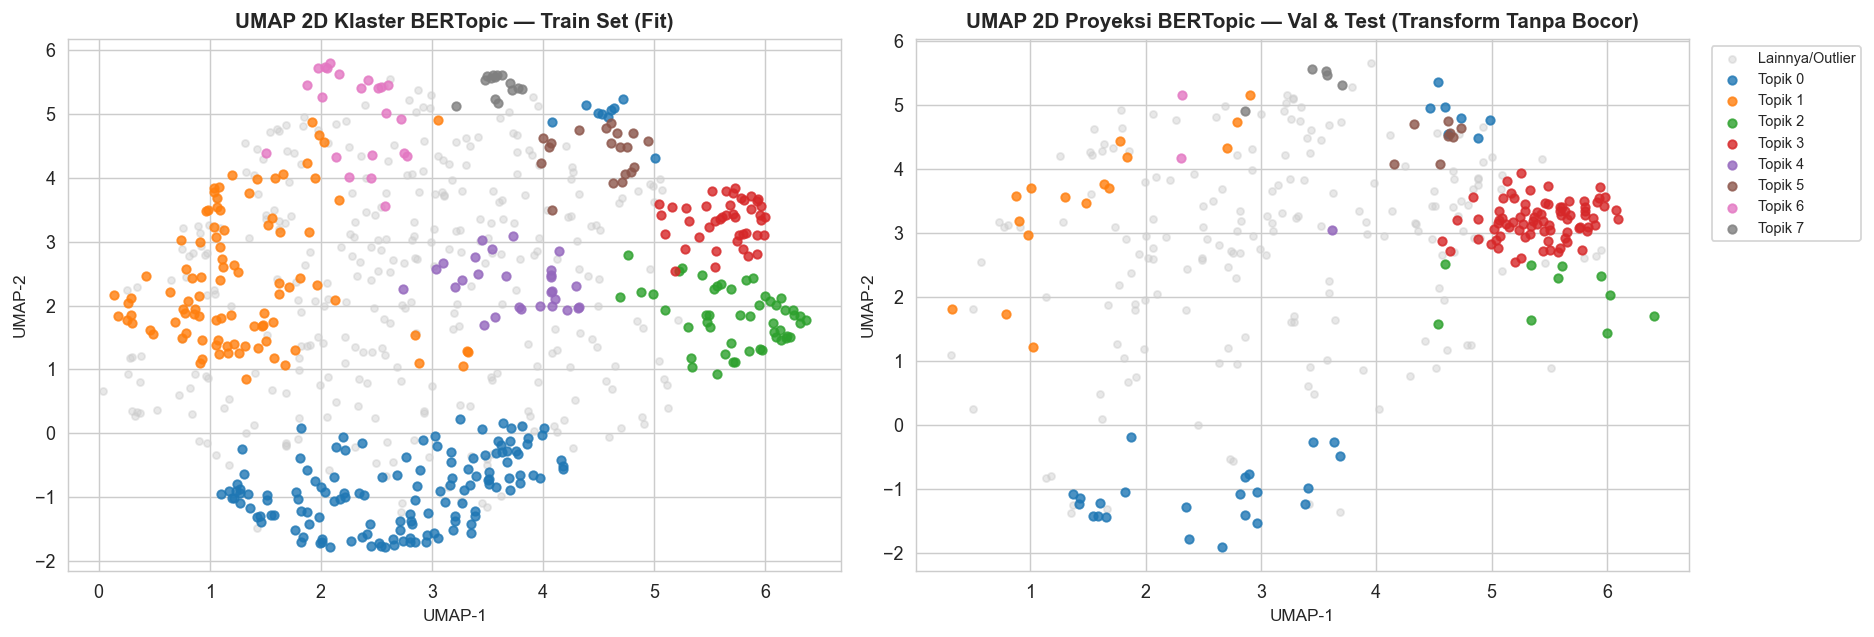

136040

In [6]:
try:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE, local_files_only=True)
except Exception:
    st_model = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
for p in st_model.parameters():
    p.requires_grad = False
st_model.eval()

daily_topic_docs = [
    f"{t}. {b[:500]}".strip() if hn == 1 else ""
    for t, b, hn in zip(df["title_clean"], df["norm_clean"], df["has_news"])
]
news_mask = df["has_news"].values == 1
tr_news_mask = is_tr & news_mask
news_docs_all = [d for d, m in zip(daily_topic_docs, news_mask) if m]

with torch.no_grad():
    news_embs_all = st_model.encode(news_docs_all, batch_size=64, show_progress_bar=False, normalize_embeddings=True)

emb_minilm_full = np.zeros((len(df), news_embs_all.shape[1]), dtype=np.float32)
emb_minilm_full[news_mask] = news_embs_all

tr_docs = [daily_topic_docs[i] for i in np.where(tr_news_mask)[0]]
tr_embs = emb_minilm_full[tr_news_mask]

umap_bt = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED)
hdbscan_bt = HDBSCAN(min_cluster_size=15, min_samples=5, metric="euclidean", cluster_selection_method="eom", prediction_data=True)
vec_bt = CountVectorizer(stop_words="english", min_df=3, ngram_range=(1, 2))

topic_model = BERTopic(
    embedding_model=st_model,
    umap_model=umap_bt,
    hdbscan_model=hdbscan_bt,
    vectorizer_model=vec_bt,
    calculate_probabilities=True,
    verbose=False,
)
tr_topics, _ = topic_model.fit_transform(tr_docs, tr_embs)
bt_info = topic_model.get_topic_info()
print(f"BERTopic di-fit pada {len(tr_docs)} hari Train berberita -> {int((bt_info['Topic'] != -1).sum())} topik.")
display(bt_info.head(10))

all_news_topics, all_news_probs = topic_model.transform(news_docs_all, emb_minilm_full[news_mask])
all_news_probs = np.asarray(all_news_probs)
if all_news_probs.ndim == 1:
    uniq_t = sorted([t for t in set(tr_topics) if t != -1])
    oh = np.zeros((len(all_news_topics), max(len(uniq_t), 1)), dtype=np.float32)
    tmap = {t: j for j, t in enumerate(uniq_t)}
    for r_i, tv in enumerate(all_news_topics):
        if tv in tmap:
            oh[r_i, tmap[tv]] = 1.0
    all_news_probs = oh

topic_prob_full = np.zeros((len(df), all_news_probs.shape[1]), dtype=np.float32)
topic_prob_full[news_mask] = all_news_probs
df["bt_topic"] = -2
df.loc[news_mask, "bt_topic"] = all_news_topics

# Reduksi dimensi probabilitas topik dengan PCA (fit di Train)
TOPIC_PCA_DIM = min(5, topic_prob_full.shape[1])
sc_top = StandardScaler().fit(topic_prob_full[is_tr])
pca_top = PCA(n_components=TOPIC_PCA_DIM, random_state=SEED).fit(sc_top.transform(topic_prob_full[is_tr]))
top_pca = pca_top.transform(sc_top.transform(topic_prob_full))
topic_pca_cols = [f"topic_pca_{i}" for i in range(TOPIC_PCA_DIM)]
for i, c in enumerate(topic_pca_cols):
    df[c] = top_pca[:, i]

# Reduksi dimensi UMAP 2D (fit hanya di Train berberita)
umap_2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit(tr_embs)
umap_2d_news = umap_2d.transform(emb_minilm_full[news_mask])
df["topic_umap_0"], df["topic_umap_1"] = 0.0, 0.0
df.loc[news_mask, "topic_umap_0"] = umap_2d_news[:, 0]
df.loc[news_mask, "topic_umap_1"] = umap_2d_news[:, 1]
topic_umap_cols = ["topic_umap_0", "topic_umap_1"]

# Plot UMAP 2D Train vs Val/Test
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5))
top_ids = bt_info[bt_info["Topic"] != -1]["Topic"].head(8).tolist()
cmap_t = {tid: sns.color_palette("tab10", len(top_ids))[i] for i, tid in enumerate(top_ids)}
for ax, mask_sub, title in [
    (axes[0], tr_news_mask, "UMAP 2D Klaster BERTopic — Train Set (Fit)"),
    (axes[1], (is_va | is_te) & news_mask, "UMAP 2D Proyeksi BERTopic — Val & Test (Transform Tanpa Bocor)"),
]:
    sub = df.loc[mask_sub]
    m_o = ~sub["bt_topic"].isin(top_ids)
    ax.scatter(sub.loc[m_o, "topic_umap_0"], sub.loc[m_o, "topic_umap_1"], c="#cccccc", s=15, alpha=0.45, label="Lainnya/Outlier")
    for tid in top_ids:
        mt = sub["bt_topic"] == tid
        if mt.sum() > 0:
            ax.scatter(sub.loc[mt, "topic_umap_0"], sub.loc[mt, "topic_umap_1"], color=cmap_t[tid], s=22, alpha=0.8, label=f"Topik {tid}")
    ax.set_title(title)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

del st_model
gc.collect()

## 6. Stage 1 Classifier Arah Return (Tuning di Val + 5-Fold OOF di Train)

Menggabungkan **BERT Title PCA**, **DeBERTa Title PCA**, **Sentimen Kontinu (FinBERT + DeBERTa)**, dan **Topik BERTopic (PCA + UMAP)** untuk memprediksi arah return USD/IDR.

In [7]:
sent_s1_cols = both_cont_cols

s1_grid = []
for n_b, n_d in [(4, 4), (8, 4), (4, 8), (8, 8)]:
    for c_v in [0.02, 0.05, 0.1, 0.2, 0.5]:
        s1_grid.append((
            f"LogReg(C={c_v}, b={n_b}, d={n_d})",
            n_b, n_d,
            lambda c=c_v: LogisticRegression(C=c, class_weight="balanced", max_iter=1000, random_state=SEED),
        ))
    for ne, md, lr_g in [(60, 2, 0.03), (100, 2, 0.03)]:
        s1_grid.append((
            f"GradBoost(n={ne}, d={md}, b={n_b}, d={n_d})",
            n_b, n_d,
            lambda n=ne, d=md, l=lr_g: GradientBoostingClassifier(n_estimators=n, max_depth=d, learning_rate=l, subsample=0.8, random_state=SEED),
        ))

s1_rows = []
for name, nb, nd, fac in s1_grid:
    cols_k = bert_pca_cols[:nb] + deberta_pca_cols[:nd] + sent_s1_cols + topic_pca_cols + topic_umap_cols
    sc_k = StandardScaler().fit(df.loc[is_tr, cols_k])
    clf_k = fac().fit(sc_k.transform(df.loc[is_tr, cols_k]), y_tr_dir)
    p_va = clf_k.predict_proba(sc_k.transform(df.loc[is_va, cols_k]))[:, 1]
    s1_rows.append({
        "Model": name, "nb": nb, "nd": nd,
        "Val Acc (%)": round(accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_va >= 0.5).astype(int)) * 100, 2),
        "Val ROC-AUC": round(roc_auc_score(y_va_dir, p_va), 4),
    })

s1_tune_df = pd.DataFrame(s1_rows).sort_values(["Val BalAcc (%)", "Val ROC-AUC"], ascending=False).reset_index(drop=True)
best_s1_name = s1_tune_df.iloc[0]["Model"]
best_nb, best_nd, best_s1_fac = next((nb, nd, fac) for nm, nb, nd, fac in s1_grid if nm == best_s1_name)
stage1_cols = bert_pca_cols[:best_nb] + deberta_pca_cols[:best_nd] + sent_s1_cols + topic_pca_cols + topic_umap_cols

print(f"Stage 1 Terbaik (Val): {best_s1_name} ({len(stage1_cols)} fitur)")
display(s1_tune_df.head(8))

# 5-Fold OOF di dalam Train untuk mencegah leakage ke Stage 2
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_tr_prob = np.zeros(len(y_tr_dir), dtype=np.float32)
for tr_f, ho_f in skf.split(df.loc[is_tr, stage1_cols], y_tr_dir):
    sc_f = StandardScaler().fit(df.loc[is_tr, stage1_cols].iloc[tr_f])
    clf_f = best_s1_fac().fit(sc_f.transform(df.loc[is_tr, stage1_cols].iloc[tr_f]), y_tr_dir[tr_f])
    oof_tr_prob[ho_f] = clf_f.predict_proba(sc_f.transform(df.loc[is_tr, stage1_cols].iloc[ho_f]))[:, 1]

sc_s1 = StandardScaler().fit(df.loc[is_tr, stage1_cols])
final_s1 = best_s1_fac().fit(sc_s1.transform(df.loc[is_tr, stage1_cols]), y_tr_dir)
p_s1_va = final_s1.predict_proba(sc_s1.transform(df.loc[is_va, stage1_cols]))[:, 1]
p_s1_te = final_s1.predict_proba(sc_s1.transform(df.loc[is_te, stage1_cols]))[:, 1]

df.loc[is_tr, "pred_dir_prob"] = oof_tr_prob
df.loc[is_va, "pred_dir_prob"] = p_s1_va
df.loc[is_te, "pred_dir_prob"] = p_s1_te
df["pred_dir_class"] = (df["pred_dir_prob"] >= 0.5).astype(int)
df["pred_dir_signed"] = 2.0 * df["pred_dir_prob"] - 1.0

s1_eval_df = pd.DataFrame([
    {"Split": "Train (5-Fold OOF)", "Acc (%)": round(accuracy_score(y_tr_dir, (oof_tr_prob >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_tr_dir, (oof_tr_prob >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_tr_dir, oof_tr_prob), 4)},
    {"Split": "Validation", "Acc (%)": round(accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_va_dir, (p_s1_va >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_va_dir, p_s1_va), 4)},
    {"Split": "Test", "Acc (%)": round(accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "BalAcc (%)": round(balanced_accuracy_score(y_te_dir, (p_s1_te >= 0.5).astype(int)) * 100, 2),
     "ROC-AUC": round(roc_auc_score(y_te_dir, p_s1_te), 4)},
])
display(s1_eval_df)

Stage 1 Terbaik (Val): LogReg(C=0.02, b=4, d=8) (34 fitur)


,Model,nb,nd,Val Acc (%),Val BalAcc (%),Val ROC-AUC
0,"LogReg(C=0.02, b=4, d=8)",4,8,56.11,57.22,0.5564
1,"LogReg(C=0.2, b=4, d=8)",4,8,56.11,56.92,0.5433
2,"LogReg(C=0.05, b=4, d=8)",4,8,55.00,55.95,0.5510
3,"LogReg(C=0.1, b=4, d=8)",4,8,55.00,55.95,0.5466
4,"LogReg(C=0.5, b=4, d=8)",4,8,55.00,55.73,0.5376
5,"LogReg(C=0.5, b=8, d=4)",8,4,53.33,54.09,0.5051
6,"LogReg(C=0.02, b=8, d=8)",8,8,52.78,54.02,0.5281
7,"LogReg(C=0.5, b=8, d=8)",8,8,53.33,54.02,0.5042


,Split,Acc (%),BalAcc (%),ROC-AUC
0,Train (5-Fold OOF),53.33,53.10,0.5462
1,Validation,56.11,57.22,0.5564
2,Test,56.35,56.46,0.5524


## 7. Fitur Interaksi `Sentimen × Arah` (Tinggi & Ekstrem — Penguatan Penurunan/Kenaikan Ekstrem)

Ambang kuantil dihitung **murni pada hari berberita di Train Set**:
- **Sentimen Tinggi (`HIGH_SENT_THRES` = kuantil ke-70 Train)**: `flag_naik_sent_tinggi`, `flag_turun_sent_tinggi`.
- **Sentimen Ekstrem (`EXTREME_SENT_THRES` = kuantil ke-90 Train)**:
  - `flag_naik_ekstrem`: prediksi Naik dengan sentimen negatif ekstrem (`sent_magnitude >= EXTREME_SENT_THRES`).
  - `flag_turun_ekstrem`: prediksi Turun dengan sentimen positif ekstrem $\rightarrow$ memberi sinyal penekanan kuat menuju **penurunan kurs yang ekstrem** (`extreme_turun_pressure = flag_turun_ekstrem * (-sent_magnitude)`).
  - `extreme_amp_x_dir`: amplifikasi non-linear $\text{sign}(\text{sent\_x\_dir}) \cdot |\text{sent\_x\_dir}|^2$.

Ambang Sentimen Tinggi  (Q70 Train): 0.5548
Ambang Sentimen Ekstrem (Q90 Train): 0.9097


,Split,Tier,Hari,Mean LogRet Aktual,Aktual Naik (%)
0,Train,-2: Ekstrem Turun,50,-0.000446,54.0
1,Train,-1: Tinggi Turun,96,-0.000367,51.0
2,Train,0: Netral/Rendah,621,0.000267,55.7
3,Train,+1: Tinggi Naik,50,0.000616,66.0
4,Train,+2: Ekstrem Naik,23,-0.000632,43.5
5,Val,-2: Ekstrem Turun,13,0.000385,53.8
6,Val,-1: Tinggi Turun,13,0.000662,53.8
7,Val,0: Netral/Rendah,143,0.000150,53.8
8,Val,+1: Tinggi Naik,9,-0.000310,44.4
9,Val,+2: Ekstrem Naik,2,0.000062,50.0


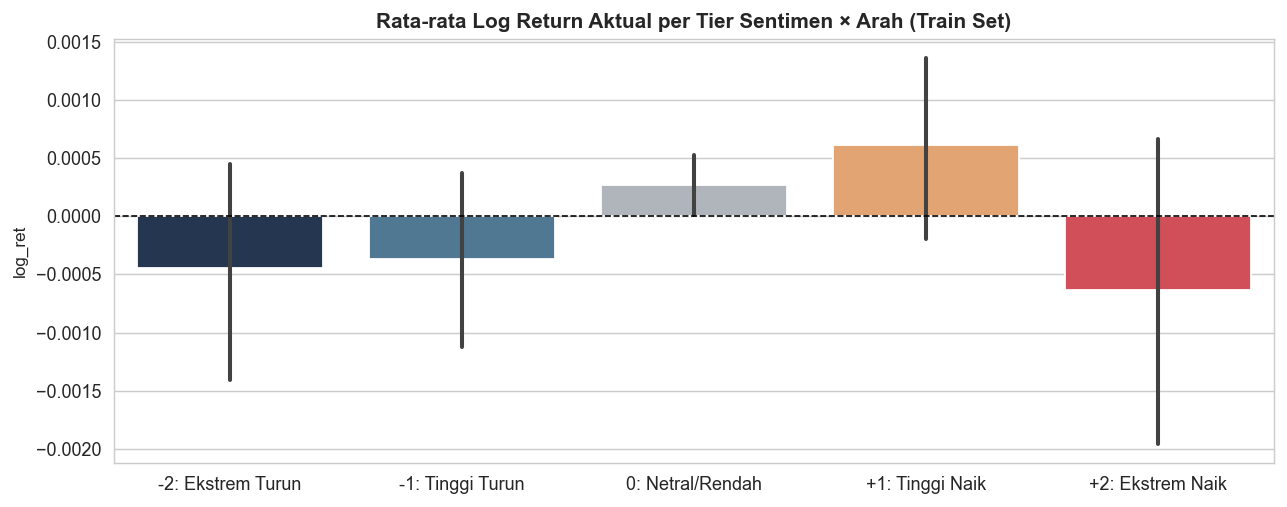

In [8]:
tr_mags = df.loc[is_tr & (df["has_news"] == 1), "sent_magnitude"].values
HIGH_SENT_THRES = float(np.quantile(tr_mags, 0.70))
EXTREME_SENT_THRES = float(np.quantile(tr_mags, 0.90))
print(f"Ambang Sentimen Tinggi  (Q70 Train): {HIGH_SENT_THRES:.4f}")
print(f"Ambang Sentimen Ekstrem (Q90 Train): {EXTREME_SENT_THRES:.4f}")

df["sent_x_dir"] = df["kurs_pressure"] * df["pred_dir_signed"]
df["sent_mag_x_dir"] = df["sent_magnitude"] * df["pred_dir_signed"]
df["extreme_amp_x_dir"] = np.sign(df["sent_x_dir"]) * (np.abs(df["sent_x_dir"]) ** 2)

is_high = df["sent_magnitude"] >= HIGH_SENT_THRES
is_ext = df["sent_magnitude"] >= EXTREME_SENT_THRES

df["flag_naik_sent_tinggi"] = ((df["pred_dir_class"] == 1) & is_high).astype(int)
df["flag_turun_sent_tinggi"] = ((df["pred_dir_class"] == 0) & is_high).astype(int)
df["flag_naik_ekstrem"] = ((df["pred_dir_class"] == 1) & is_ext).astype(int)
df["flag_turun_ekstrem"] = ((df["pred_dir_class"] == 0) & is_ext).astype(int)

# Sinyal khusus amplifikasi ekstrem ke penurunan & kenaikan
df["extreme_turun_pressure"] = df["flag_turun_ekstrem"] * (-df["sent_magnitude"])
df["extreme_naik_pressure"] = df["flag_naik_ekstrem"] * (df["sent_magnitude"])

# 5 Tier: -2 (Ekstrem Turun), -1 (Tinggi Turun), 0 (Netral/Rendah), +1 (Tinggi Naik), +2 (Ekstrem Naik)
df["sent_dir_5tier"] = (
    df["flag_naik_sent_tinggi"] + df["flag_naik_ekstrem"]
    - df["flag_turun_sent_tinggi"] - df["flag_turun_ekstrem"]
)
tier5_map = {
    -2: "-2: Ekstrem Turun",
    -1: "-1: Tinggi Turun",
    0: "0: Netral/Rendah",
    1: "+1: Tinggi Naik",
    2: "+2: Ekstrem Naik",
}
df["sent_dir_5tier_label"] = df["sent_dir_5tier"].map(tier5_map)

tier_rows = []
for sp_n, m in [("Train", is_tr), ("Val", is_va), ("Test", is_te)]:
    sub = df.loc[m]
    for tv in [-2, -1, 0, 1, 2]:
        g = sub[sub["sent_dir_5tier"] == tv]
        tier_rows.append({
            "Split": sp_n,
            "Tier": tier5_map[tv],
            "Hari": len(g),
            "Mean LogRet Aktual": round(float(g["log_ret"].mean()), 6) if len(g) > 0 else np.nan,
            "Aktual Naik (%)": round(float(g["y_dir"].mean() * 100), 1) if len(g) > 0 else np.nan,
        })
display(pd.DataFrame(tier_rows))

fig, ax = plt.subplots(figsize=(10, 4))
order_5 = [tier5_map[k] for k in [-2, -1, 0, 1, 2]]
sns.barplot(data=df.loc[is_tr], x="sent_dir_5tier_label", y="log_ret", order=order_5,
            palette=["#1d3557", "#457b9d", "#adb5bd", "#f4a261", "#e63946"], ax=ax)
ax.axhline(0, color="black", linestyle="--", lw=0.9)
ax.set_title("Rata-rata Log Return Aktual per Tier Sentimen × Arah (Train Set)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 8. Penggabungan dengan Fitur Time Series (Strictly Causal $\le t-1$) & Definisi Kelompok Fitur

Menyusun 14 fitur *time series* (*lagged return*, volatilitas *rolling*, deviasi MA5/10/20, RSI 14, *streak* naik/turun, spread, dan hari perdagangan) serta mengelompokkan fitur secara eksplisit untuk **Studi Ablasi**.

In [9]:
df["ret_lag1"] = df["log_ret"].shift(1)
df["ret_lag2"] = df["log_ret"].shift(2)
df["ret_lag3"] = df["log_ret"].shift(3)
df["ret_lag5"] = df["log_ret"].shift(5)
df["vol_5d"] = df["log_ret"].shift(1).rolling(5).std()
df["vol_10d"] = df["log_ret"].shift(1).rolling(10).std()

for w in [5, 10, 20]:
    ma_w = df["rate_mid"].shift(1).rolling(w).mean()
    df[f"dist_ma{w}"] = df["rate_mid"].shift(1) / ma_w - 1.0

delta = df["rate_mid"].diff().shift(1)
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
df["rsi_14"] = (100.0 - (100.0 / (1.0 + gain / (loss + 1e-9)))) / 100.0

consecs, cur = [], 0
for r in df["log_ret"]:
    cur = (cur + 1 if cur > 0 else 1) if r > 0 else ((cur - 1 if cur < 0 else -1) if r < 0 else 0)
    consecs.append(cur)
df["consec_up_days"] = pd.Series(consecs, index=df.index).shift(1)
df["spread_lag1"] = ((df["Kurs Jual"] - df["Kurs Beli"]) / df["rate_mid"]).shift(1)
dow = df[date_col].dt.dayofweek
df["dow_sin"] = np.sin(2 * np.pi * dow / 5.0)
df["dow_cos"] = np.cos(2 * np.pi * dow / 5.0)

# Definisi kelompok fitur untuk studi ablasi & pemodelan
GRP_TS = [
    "ret_lag1", "ret_lag2", "ret_lag3", "ret_lag5",
    "vol_5d", "vol_10d", "dist_ma5", "dist_ma10", "dist_ma20",
    "rsi_14", "consec_up_days", "spread_lag1", "dow_sin", "dow_cos",
]
GRP_BERT_TITLE = bert_pca_cols[:4]
GRP_DEBERTA_TITLE = deberta_pca_cols[:4]
GRP_FINBERT_SENT = [
    "finbert_kurs_pressure", "finbert_sent_magnitude", "finbert_pos", "finbert_neg", "finbert_neu",
]
GRP_DEBERTA_SENT = [
    "deberta_kurs_pressure", "deberta_sent_magnitude", "deberta_pos", "deberta_neg", "deberta_neu",
]
GRP_SENT_INTER = [
    "kurs_pressure", "sent_magnitude", "has_news",
    "pred_dir_prob", "pred_dir_signed",
    "sent_x_dir", "sent_mag_x_dir", "extreme_amp_x_dir",
    "flag_naik_sent_tinggi", "flag_turun_sent_tinggi",
    "flag_naik_ekstrem", "flag_turun_ekstrem",
    "extreme_turun_pressure", "extreme_naik_pressure", "sent_dir_5tier",
]
GRP_SENT_ALL = list(dict.fromkeys(GRP_FINBERT_SENT + GRP_DEBERTA_SENT + GRP_SENT_INTER))
GRP_BERTOPIC = topic_pca_cols + topic_umap_cols

FULL_COLS = GRP_TS + GRP_BERT_TITLE + GRP_DEBERTA_TITLE + GRP_SENT_ALL + GRP_BERTOPIC
df_model = df.dropna(subset=FULL_COLS + ["log_ret"]).reset_index(drop=True)

m_tr = (df_model[date_col] <= train_end_date).values
m_va = ((df_model[date_col] > train_end_date) & (df_model[date_col] <= val_end_date)).values
m_te = (df_model[date_col] > val_end_date).values

print(f"Baris valid Stage 2: {len(df_model):,} | Train={m_tr.sum()}, Val={m_va.sum()}, Test={m_te.sum()}")
print(
    f"Ringkasan jumlah fitur ({len(FULL_COLS)} total): "
    f"TS={len(GRP_TS)}, BERT-Title={len(GRP_BERT_TITLE)}, DeBERTa-Title={len(GRP_DEBERTA_TITLE)}, "
    f"FinBERT+DeBERTa+Sent×Arah={len(GRP_SENT_ALL)}, BERTopic={len(GRP_BERTOPIC)}"
)

def build_sequences(frame: pd.DataFrame, feature_cols: list[str], seq_len: int):
    sc_x = StandardScaler().fit(frame.loc[m_tr, feature_cols])
    X_scaled = sc_x.transform(frame[feature_cols]).astype(np.float32)
    y_raw = frame["log_ret"].values.astype(np.float32)
    mu_y = float(y_raw[m_tr].mean())
    std_y = float(y_raw[m_tr].std() + 1e-9)
    y_scaled = ((y_raw - mu_y) / std_y).astype(np.float32)

    X_seqs, y_seqs_s, y_seqs_raw, seq_splits, seq_dates, prev_rates, curr_rates = [], [], [], [], [], [], []
    split_arr = np.where(m_tr, "train", np.where(m_va, "val", "test"))
    dates_arr = frame[date_col].values
    rates_arr = frame["rate_mid"].values

    for t in range(seq_len - 1, len(frame)):
        X_seqs.append(X_scaled[t - seq_len + 1 : t + 1])
        y_seqs_s.append(y_scaled[t])
        y_seqs_raw.append(y_raw[t])
        seq_splits.append(split_arr[t])
        seq_dates.append(dates_arr[t])
        prev_rates.append(rates_arr[t - 1])
        curr_rates.append(rates_arr[t])

    return {
        "X": np.array(X_seqs, dtype=np.float32),
        "y_s": np.array(y_seqs_s, dtype=np.float32),
        "y_raw": np.array(y_seqs_raw, dtype=np.float32),
        "split": np.array(seq_splits),
        "dates": pd.to_datetime(seq_dates),
        "prev_rate": np.array(prev_rates, dtype=np.float64),
        "curr_rate": np.array(curr_rates, dtype=np.float64),
        "mu_y": mu_y,
        "std_y": std_y,
    }

Baris valid Stage 2: 1,181 | Train=820, Val=180, Test=181
Ringkasan jumlah fitur (54 total): TS=14, BERT-Title=4, DeBERTa-Title=4, FinBERT+DeBERTa+Sent×Arah=25, BERTopic=7


## 9. Pemodelan Neural (MLP, LSTM, Bi-LSTM) & Hyperparameter Tuning Model Terbaik

Melatih dan men-tuning **MLP**, **LSTM** (*unidirectional*), dan **Bi-LSTM** (*bidirectional*) pada **Validation Set**, lalu melakukan **Fine-Grained Hyperparameter Tuning** pada arsitektur terbaik sebelum mengevaluasinya pada **Test Set**.

In [10]:
class TabularMLPRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, dropout: float = 0.35):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class SeqLSTMRegressor(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32, num_layers: int = 1,
                 dropout: float = 0.35, bidirectional: bool = True):
        super().__init__()
        self.in_norm = nn.LayerNorm(input_dim)
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.head = nn.Sequential(
            nn.LayerNorm(out_dim),
            nn.Dropout(dropout),
            nn.Linear(out_dim, 16),
            nn.Tanh(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        x = self.in_norm(x)
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_pytorch_regressor(model: nn.Module, X_tr_np, y_tr_s_np, X_va_np, y_va_s_np, X_te_np,
                            mu_y: float, std_y: float, lr: float = 1e-3, weight_decay: float = 1e-3,
                            dir_lambda: float = 0.15, batch_size: int = 32, epochs: int = 70, patience: int = 12):
    set_seed(SEED)
    X_tr = torch.tensor(X_tr_np, dtype=torch.float32)
    y_tr = torch.tensor(y_tr_s_np, dtype=torch.float32)
    X_va = torch.tensor(X_va_np, dtype=torch.float32).to(DEVICE)
    y_va = torch.tensor(y_va_s_np, dtype=torch.float32).to(DEVICE)
    X_te = torch.tensor(X_te_np, dtype=torch.float32).to(DEVICE)

    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def composite_loss(pred_s, target_s):
        mse = nn.functional.mse_loss(pred_s, target_s)
        zero_s = -mu_y / std_y
        sign_hinge = torch.relu(-(pred_s - zero_s) * torch.sign(target_s - zero_s)).mean()
        return mse + dir_lambda * sign_hinge

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    wait = 0
    tr_hist, va_hist = [], []

    for _ in range(epochs):
        model.train()
        ep_losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = composite_loss(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            ep_losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            va_loss = float(composite_loss(model(X_va), y_va).item())

        tr_hist.append(float(np.mean(ep_losses)))
        va_hist.append(va_loss)

        if va_loss < best_val_loss - 1e-6:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_va_raw = model(X_va).cpu().numpy() * std_y + mu_y
        pred_te_raw = model(X_te).cpu().numpy() * std_y + mu_y

    return {
        "pred_va": pred_va_raw,
        "pred_te": pred_te_raw,
        "tr_hist": tr_hist,
        "va_hist": va_hist,
        "best_epoch": len(tr_hist) - wait,
    }


def eval_reg(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    dt, dp = (y_true > 0).astype(int), (y_pred > 0).astype(int)
    return {
        "Model": name,
        "RMSE": round(rmse, 6),
        "MAE": round(mae, 6),
        "R2": round(r2, 4),
        "DirAcc (%)": round(float(accuracy_score(dt, dp) * 100), 2),
        "BalAcc (%)": round(float(balanced_accuracy_score(dt, dp) * 100), 2),
    }

seq_full_cache = {sl: build_sequences(df_model, FULL_COLS, sl) for sl in [5, 10, 15]}
b10 = seq_full_cache[10]
sp10 = b10["split"]
X_tab_tr, X_tab_va, X_tab_te = b10["X"][sp10 == "train"][:, -1, :], b10["X"][sp10 == "val"][:, -1, :], b10["X"][sp10 == "test"][:, -1, :]
y_tab_tr_s, y_va_s = b10["y_s"][sp10 == "train"], b10["y_s"][sp10 == "val"]
y_va_true, y_te_true = b10["y_raw"][sp10 == "val"], b10["y_raw"][sp10 == "test"]
mu_y_b, std_y_b = b10["mu_y"], b10["std_y"]

# 1) Tuning MLP
mlp_grid = [
    {"hidden_dim": 16, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"hidden_dim": 32, "dropout": 0.45, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"hidden_dim": 32, "dropout": 0.30, "lr": 1e-3, "dir_lambda": 0.00, "weight_decay": 2e-3},
    {"hidden_dim": 64, "dropout": 0.45, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
]
mlp_rows, mlp_runs = [], []
for cid, cfg in enumerate(mlp_grid):
    r = train_pytorch_regressor(
        TabularMLPRegressor(X_tab_tr.shape[1], hidden_dim=cfg["hidden_dim"], dropout=cfg["dropout"]),
        X_tab_tr, y_tab_tr_s, X_tab_va, y_va_s, X_tab_te,
        mu_y_b, std_y_b, lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
    )
    m = eval_reg(f"MLP #{cid}", y_va_true, r["pred_va"])
    mlp_rows.append({"arch": "MLP", "cfg_id": cid, **cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
    mlp_runs.append(r)

# 2) Tuning LSTM & Bi-LSTM
seq_grid = [
    {"seq_len": 5,  "hidden_dim": 16, "num_layers": 1, "dropout": 0.25, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 5,  "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 1e-3, "dir_lambda": 0.25, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 16, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.30, "lr": 1e-3, "dir_lambda": 0.15, "weight_decay": 1e-3},
    {"seq_len": 10, "hidden_dim": 32, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 2e-3},
    {"seq_len": 10, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.15, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 32, "num_layers": 1, "dropout": 0.35, "lr": 5e-4, "dir_lambda": 0.25, "weight_decay": 2e-3},
    {"seq_len": 15, "hidden_dim": 64, "num_layers": 1, "dropout": 0.40, "lr": 5e-4, "dir_lambda": 0.30, "weight_decay": 3e-3},
]

def tune_seq_arch(bidir: bool, arch_name: str):
    rows, runs = [], []
    for cid, cfg in enumerate(seq_grid):
        b = seq_full_cache[cfg["seq_len"]]
        sp = b["split"]
        tr_i, va_i, te_i = sp == "train", sp == "val", sp == "test"
        r = train_pytorch_regressor(
            SeqLSTMRegressor(b["X"].shape[2], cfg["hidden_dim"], cfg["num_layers"], cfg["dropout"], bidirectional=bidir),
            b["X"][tr_i], b["y_s"][tr_i], b["X"][va_i], b["y_s"][va_i], b["X"][te_i],
            b["mu_y"], b["std_y"], lr=cfg["lr"], weight_decay=cfg["weight_decay"], dir_lambda=cfg["dir_lambda"],
        )
        m = eval_reg(f"{arch_name} #{cid}", b["y_raw"][va_i], r["pred_va"])
        rows.append({"arch": arch_name, "cfg_id": cid, **cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
        runs.append(r)
    return rows, runs

lstm_rows, lstm_runs = tune_seq_arch(False, "LSTM")
bilstm_rows, bilstm_runs = tune_seq_arch(True, "Bi-LSTM")

def pick_best(rows, runs):
    d = pd.DataFrame(rows)
    d["Val Score"] = (d["Val BalAcc (%)"] - 2500.0 * (d["Val RMSE"] - d["Val RMSE"].min())).round(3)
    d = d.sort_values("Val Score", ascending=False).reset_index(drop=True)
    cid = int(d.iloc[0]["cfg_id"])
    return d, runs[cid], d.iloc[0].to_dict()

mlp_df, res_mlp_best, best_mlp_meta = pick_best(mlp_rows, mlp_runs)
lstm_df, res_lstm_best, best_lstm_meta = pick_best(lstm_rows, lstm_runs)
bilstm_df, res_bilstm_best, best_bilstm_meta = pick_best(bilstm_rows, bilstm_runs)

# Pilih arsitektur terbaik berdasarkan Validation Score
arch_ranking = pd.DataFrame([best_mlp_meta, best_lstm_meta, best_bilstm_meta])
arch_ranking["Val Score"] = (arch_ranking["Val BalAcc (%)"] - 2500.0 * (arch_ranking["Val RMSE"] - arch_ranking["Val RMSE"].min())).round(3)
arch_ranking = arch_ranking.sort_values("Val Score", ascending=False).reset_index(drop=True)
best_arch_name = arch_ranking.iloc[0]["arch"]
print(f"Arsitektur terbaik pada Validation Set: {best_arch_name}")
display(arch_ranking[["arch", "Val RMSE", "Val DirAcc (%)", "Val BalAcc (%)", "Val Score", "best_epoch"]])

# --- Fine-Grained Hyperparameter Tuning Lanjutan untuk Model Terbaik ---
best_meta_row = arch_ranking.iloc[0]
fine_rows, fine_runs, fine_cfgs = [], [], []
if best_arch_name == "MLP":
    base_hd = int(best_meta_row["hidden_dim"])
    for hd in sorted({max(16, base_hd // 2), base_hd, min(64, base_hd * 2)}):
        for dr in [0.25, 0.35, 0.45]:
            for dl in [0.10, 0.25]:
                for lr_v in [5e-4, 1e-3]:
                    cfg = {"hidden_dim": hd, "dropout": dr, "dir_lambda": dl, "lr": lr_v, "weight_decay": 2e-3, "batch_size": 32}
                    r = train_pytorch_regressor(
                        TabularMLPRegressor(X_tab_tr.shape[1], hd, dr),
                        X_tab_tr, y_tab_tr_s, X_tab_va, y_va_s, X_tab_te,
                        mu_y_b, std_y_b, lr=lr_v, weight_decay=2e-3, dir_lambda=dl,
                    )
                    m = eval_reg("fine", y_va_true, r["pred_va"])
                    fine_rows.append({**cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
                    fine_runs.append(r)
                    fine_cfgs.append(cfg)
else:
    bidir_flag = (best_arch_name == "Bi-LSTM")
    base_sl = int(best_meta_row["seq_len"])
    base_hd = int(best_meta_row["hidden_dim"])
    for sl in sorted({max(5, base_sl - 5), base_sl, min(15, base_sl + 5)}):
        b = seq_full_cache[sl]
        sp = b["split"]
        tr_i, va_i, te_i = sp == "train", sp == "val", sp == "test"
        for hd in sorted({base_hd, 32, 64}):
            for dr in [0.30, 0.40]:
                for dl in [0.15, 0.30]:
                    cfg = {"seq_len": sl, "hidden_dim": hd, "num_layers": 1, "dropout": dr, "dir_lambda": dl, "lr": float(best_meta_row["lr"]), "weight_decay": 2e-3}
                    r = train_pytorch_regressor(
                        SeqLSTMRegressor(b["X"].shape[2], hd, 1, dr, bidirectional=bidir_flag),
                        b["X"][tr_i], b["y_s"][tr_i], b["X"][va_i], b["y_s"][va_i], b["X"][te_i],
                        b["mu_y"], b["std_y"], lr=cfg["lr"], weight_decay=2e-3, dir_lambda=dl,
                    )
                    m = eval_reg("fine", b["y_raw"][va_i], r["pred_va"])
                    fine_rows.append({**cfg, "Val RMSE": m["RMSE"], "Val BalAcc (%)": m["BalAcc (%)"], "Val DirAcc (%)": m["DirAcc (%)"], "best_epoch": r["best_epoch"]})
                    fine_runs.append(r)
                    fine_cfgs.append(cfg)

fine_df = pd.DataFrame(fine_rows)
fine_df["Val Score"] = (fine_df["Val BalAcc (%)"] - 2500.0 * (fine_df["Val RMSE"] - fine_df["Val RMSE"].min())).round(3)
fine_df = fine_df.sort_values("Val Score", ascending=False).reset_index(drop=True)
best_fine_idx = int(fine_df.index[0])
# Ambil indeks asli sebelum sort
orig_best_idx = int(pd.DataFrame(fine_rows).assign(Val_Score=lambda x: x["Val BalAcc (%)"] - 2500.0 * (x["Val RMSE"] - x["Val RMSE"].min())).sort_values("Val_Score", ascending=False).index[0])
res_best_tuned = fine_runs[orig_best_idx]
best_fine_cfg = fine_cfgs[orig_best_idx]

print(f"\nFine-Tuned {best_arch_name} Terbaik ({len(fine_rows)} kombinasi di Val): {best_fine_cfg} (epoch={res_best_tuned['best_epoch']})")
display(fine_df.head(6))

# Evaluasi perbandingan MLP vs LSTM vs Bi-LSTM vs Fine-Tuned Best Model di Test Set
mu_train_raw = float(b10["y_raw"][sp10 == "train"].mean())
neural_test_df = pd.DataFrame([
    eval_reg("Baseline: Tebak Return 0", y_te_true, np.zeros_like(y_te_true)),
    eval_reg("Baseline: Mean Train", y_te_true, np.full_like(y_te_true, mu_train_raw)),
    eval_reg("Tuned MLP (Multimodal)", y_te_true, res_mlp_best["pred_te"]),
    eval_reg("Tuned LSTM (Multimodal)", y_te_true, res_lstm_best["pred_te"]),
    eval_reg("Tuned Bi-LSTM (Multimodal)", y_te_true, res_bilstm_best["pred_te"]),
    eval_reg(f"Fine-Tuned Best ({best_arch_name})", y_te_true, res_best_tuned["pred_te"]),
]).set_index("Model")

print("\n=== PERBANDINGAN MLP vs LSTM vs Bi-LSTM & FINE-TUNED MODEL (TEST SET) ===")
display(neural_test_df)

Arsitektur terbaik pada Validation Set: Bi-LSTM


,arch,Val RMSE,Val DirAcc (%),Val BalAcc (%),Val Score,best_epoch
0,Bi-LSTM,0.003356,60.00,59.60,59.600,2
1,LSTM,0.003363,55.56,56.03,56.012,5
2,MLP,0.003399,55.56,53.57,53.462,2



Fine-Tuned Bi-LSTM Terbaik (24 kombinasi di Val): {'seq_len': 5, 'hidden_dim': 32, 'num_layers': 1, 'dropout': 0.3, 'dir_lambda': 0.3, 'lr': 0.001, 'weight_decay': 0.002} (epoch=3)


,seq_len,hidden_dim,num_layers,dropout,dir_lambda,lr,weight_decay,Val RMSE,Val BalAcc (%),Val DirAcc (%),best_epoch,Val Score
0,5,32,1,0.3,0.30,0.001,0.002,0.003355,57.81,58.33,3,57.788
1,5,32,1,0.4,0.15,0.001,0.002,0.003360,57.44,57.78,3,57.405
2,5,32,1,0.4,0.30,0.001,0.002,0.003360,57.37,57.78,3,57.335
3,10,64,1,0.3,0.15,0.001,0.002,0.003383,55.88,56.11,1,55.788
4,10,32,1,0.4,0.30,0.001,0.002,0.003374,54.61,55.56,6,54.540
5,5,64,1,0.4,0.15,0.001,0.002,0.003420,54.61,54.44,1,54.425



=== PERBANDINGAN MLP vs LSTM vs Bi-LSTM & FINE-TUNED MODEL (TEST SET) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%)
Model,,,,,
Baseline: Tebak Return 0,0.002902,0.002201,-0.0125,42.54,50.00
Baseline: Mean Train,0.002888,0.002178,-0.0031,57.46,50.00
Tuned MLP (Multimodal),0.002873,0.002137,0.0075,56.91,52.05
Tuned LSTM (Multimodal),0.002908,0.002236,-0.0173,50.28,51.67
Tuned Bi-LSTM (Multimodal),0.002895,0.002177,-0.0080,56.35,53.76
Fine-Tuned Best (Bi-LSTM),0.002891,0.002204,-0.0049,56.91,56.43


## 10. Studi Ablasi Fitur Lengkap (Additive & Leave-One-Group-Out)

Menggunakan arsitektur & konfigurasi terbaik hasil tuning (`best_arch_name` + `best_fine_cfg`) untuk mengukur:
1. **Ablasi Aditif**: bertahap menambahkan `BERT Title`, `DeBERTa Title`, `Sentimen (FinBERT + DeBERTa) + Sent×Arah`, dan `BERTopic` di atas fitur Time-Series.
2. **Ablasi Leave-One-Group-Out (LOGO)**: menghapus 1 kelompok fitur (termasuk memisahkan pengaruh `BERT Title` vs `DeBERTa Title` serta `FinBERT Sentimen` vs `DeBERTa Sentimen` vs `Sent×Arah`) dari `Full Multimodal`.

In [11]:
def eval_feature_subset(subset_name: str, cols_subset: list[str]):
    if best_arch_name == "MLP":
        b = build_sequences(df_model, cols_subset, 10)
        sp = b["split"]
        r = train_pytorch_regressor(
            TabularMLPRegressor(len(cols_subset), best_fine_cfg["hidden_dim"], best_fine_cfg["dropout"]),
            b["X"][sp == "train"][:, -1, :], b["y_s"][sp == "train"],
            b["X"][sp == "val"][:, -1, :], b["y_s"][sp == "val"],
            b["X"][sp == "test"][:, -1, :],
            b["mu_y"], b["std_y"],
            lr=best_fine_cfg["lr"], weight_decay=best_fine_cfg["weight_decay"], dir_lambda=best_fine_cfg["dir_lambda"],
        )
    else:
        b = build_sequences(df_model, cols_subset, best_fine_cfg["seq_len"])
        sp = b["split"]
        r = train_pytorch_regressor(
            SeqLSTMRegressor(len(cols_subset), best_fine_cfg["hidden_dim"], 1, best_fine_cfg["dropout"], bidirectional=(best_arch_name == "Bi-LSTM")),
            b["X"][sp == "train"], b["y_s"][sp == "train"],
            b["X"][sp == "val"], b["y_s"][sp == "val"],
            b["X"][sp == "test"],
            b["mu_y"], b["std_y"],
            lr=best_fine_cfg["lr"], weight_decay=best_fine_cfg["weight_decay"], dir_lambda=best_fine_cfg["dir_lambda"],
        )
    y_t = b["y_raw"][b["split"] == "test"]
    return {**eval_reg(subset_name, y_t, r["pred_te"]), "n_fitur": len(cols_subset)}

# 1. Additive Ablation
additive_configs = [
    ("1. TS Only", GRP_TS),
    ("2. TS + BERT Title", GRP_TS + GRP_BERT_TITLE),
    ("3. TS + DeBERTa Title", GRP_TS + GRP_DEBERTA_TITLE),
    ("4. TS + BERT + DeBERTa Title", GRP_TS + GRP_BERT_TITLE + GRP_DEBERTA_TITLE),
    ("5. TS + FinBERT & Sent×Arah", GRP_TS + list(dict.fromkeys(GRP_FINBERT_SENT + GRP_SENT_INTER))),
    ("6. TS + DeBERTa Sent & Sent×Arah", GRP_TS + list(dict.fromkeys(GRP_DEBERTA_SENT + GRP_SENT_INTER))),
    ("7. TS + BERTopic (PCA/UMAP)", GRP_TS + GRP_BERTOPIC),
    ("8. Full Multimodal (Lengkap)", FULL_COLS),
]
ablation_add_df = pd.DataFrame([eval_feature_subset(n, c) for n, c in additive_configs]).set_index("Model")
print("=== STUDI ABLASI ADITIF (TEST SET) ===")
display(ablation_add_df)

# 2. Leave-One-Group-Out (LOGO) Ablation
full_rmse = ablation_add_df.loc["8. Full Multimodal (Lengkap)", "RMSE"]
full_bal = ablation_add_df.loc["8. Full Multimodal (Lengkap)", "BalAcc (%)"]

def minus_cols(group_to_drop):
    drop_set = set(group_to_drop)
    return [c for c in FULL_COLS if c not in drop_set]

logo_configs = [
    ("Tanpa TS Features", minus_cols(GRP_TS)),
    ("Tanpa BERT Title", minus_cols(GRP_BERT_TITLE)),
    ("Tanpa DeBERTa Title", minus_cols(GRP_DEBERTA_TITLE)),
    ("Tanpa FinBERT Sentimen", minus_cols(GRP_FINBERT_SENT)),
    ("Tanpa DeBERTa Sentimen", minus_cols(GRP_DEBERTA_SENT)),
    ("Tanpa Sent×Arah (Interaksi & OOF)", minus_cols(GRP_SENT_INTER)),
    ("Tanpa BERTopic", minus_cols(GRP_BERTOPIC)),
]
logo_rows = []
for lbl, cols_minus in logo_configs:
    res_l = eval_feature_subset(lbl, cols_minus)
    res_l["Delta RMSE (tanpa - full)"] = round(res_l["RMSE"] - full_rmse, 6)
    res_l["Delta BalAcc (full - tanpa)"] = round(full_bal - res_l["BalAcc (%)"], 2)
    logo_rows.append(res_l)

logo_df = pd.DataFrame(logo_rows).set_index("Model").sort_values("Delta BalAcc (full - tanpa)", ascending=False)
print("\n=== STUDI ABLASI LEAVE-ONE-GROUP-OUT (PENGARUH KELOMPOK FITUR) ===")
print("Catatan: Delta > 0 berarti menghapus kelompok fitur tersebut memperburuk performa (fitur sangat berpengaruh).")
display(logo_df)

=== STUDI ABLASI ADITIF (TEST SET) ===


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),n_fitur
Model,,,,,,
1. TS Only,0.002973,0.002270,-0.0632,50.28,48.47,14
2. TS + BERT Title,0.002954,0.002244,-0.0490,51.38,49.94,18
3. TS + DeBERTa Title,0.002976,0.002280,-0.0652,45.30,43.30,18
4. TS + BERT + DeBERTa Title,0.003012,0.002255,-0.0906,49.72,47.65,22
5. TS + FinBERT & Sent×Arah,0.002868,0.002186,0.0110,53.59,51.52,34
6. TS + DeBERTa Sent & Sent×Arah,0.002899,0.002237,-0.0106,50.83,49.46,34
7. TS + BERTopic (PCA/UMAP),0.002897,0.002168,-0.0093,55.25,53.81,21
8. Full Multimodal (Lengkap),0.002891,0.002204,-0.0049,56.91,56.43,54



=== STUDI ABLASI LEAVE-ONE-GROUP-OUT (PENGARUH KELOMPOK FITUR) ===
Catatan: Delta > 0 berarti menghapus kelompok fitur tersebut memperburuk performa (fitur sangat berpengaruh).


,RMSE,MAE,R2,DirAcc (%),BalAcc (%),n_fitur,Delta RMSE (tanpa - full),Delta BalAcc (full - tanpa)
Model,,,,,,,,
Tanpa FinBERT Sentimen,0.002889,0.002226,-0.0035,53.04,50.87,49,-0.000002,5.56
Tanpa Sent×Arah (Interaksi & OOF),0.002906,0.002227,-0.0159,53.59,52.53,39,0.000015,3.90
Tanpa DeBERTa Sentimen,0.002897,0.002171,-0.0090,55.25,53.13,49,0.000006,3.30
Tanpa BERT Title,0.002882,0.002176,0.0015,56.91,53.90,50,-0.000009,2.53
Tanpa DeBERTa Title,0.002862,0.002123,0.0147,58.01,55.71,50,-0.000029,0.72
Tanpa TS Features,0.002919,0.002170,-0.0244,59.67,56.47,40,0.000028,-0.04
Tanpa BERTopic,0.002859,0.002194,0.0168,57.46,57.08,47,-0.000032,-0.65


## 11. Visualisasi Akhir: Studi Ablasi, Perbandingan Model, & Rekonstruksi Kurs USD/IDR

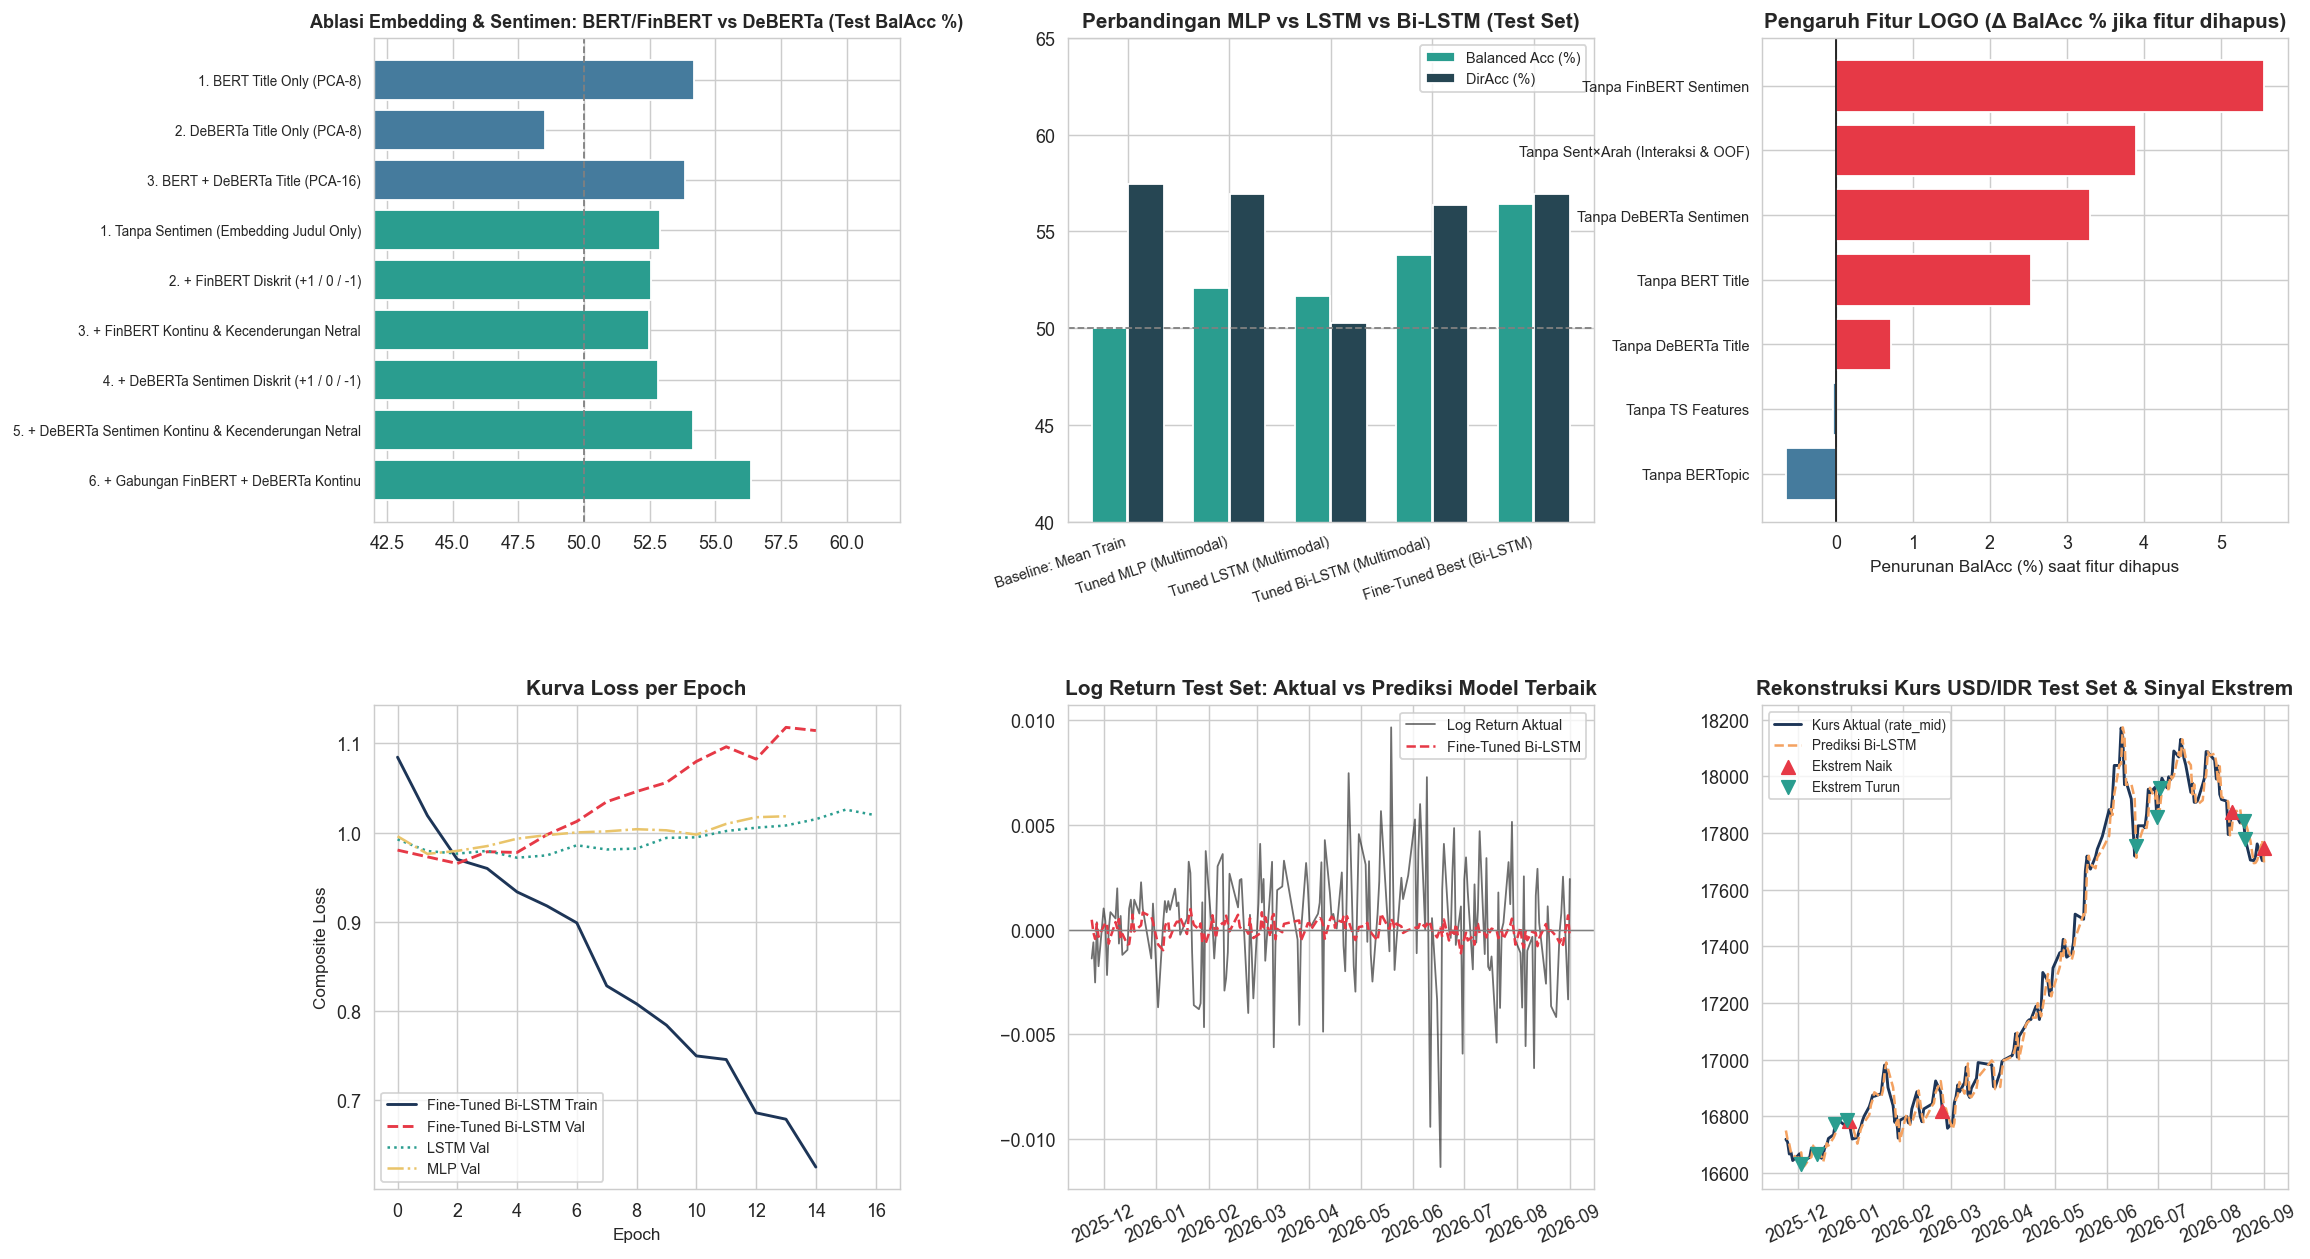

In [12]:
fig = plt.figure(figsize=(19, 11.5))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.32)

# 1. Studi Ablasi Embedding (BERT vs DeBERTa) & Sentimen (FinBERT vs DeBERTa)
ax1 = fig.add_subplot(gs[0, 0])
s1_ab_comb = pd.concat([
    emb_ablation_df[["Test BalAcc (%)"]].rename_axis("Skenario"),
    sent_ablation_df[["Test BalAcc (%)"]].rename_axis("Skenario"),
])
ax1.barh(s1_ab_comb.index, s1_ab_comb["Test BalAcc (%)"], color=["#457b9d"]*3 + ["#2a9d8f"]*6)
ax1.axvline(50.0, color="gray", linestyle="--", lw=1)
ax1.invert_yaxis()
ax1.set_xlim(42, max(62, s1_ab_comb["Test BalAcc (%)"].max() + 3))
ax1.set_title("Ablasi Embedding & Sentimen: BERT/FinBERT vs DeBERTa (Test BalAcc %)", fontsize=10)
ax1.tick_params(axis="y", labelsize=7.5)

# 2. Perbandingan MLP vs LSTM vs Bi-LSTM vs Fine-Tuned Best
ax2 = fig.add_subplot(gs[0, 1])
p_nn = neural_test_df.drop(["Baseline: Tebak Return 0"])
x_p = np.arange(len(p_nn))
ax2.bar(x_p - 0.18, p_nn["BalAcc (%)"], 0.35, label="Balanced Acc (%)", color="#2a9d8f")
ax2.bar(x_p + 0.18, p_nn["DirAcc (%)"], 0.35, label="DirAcc (%)", color="#264653")
ax2.axhline(50.0, color="gray", linestyle="--", lw=1)
ax2.set_xticks(x_p)
ax2.set_xticklabels(p_nn.index, rotation=18, ha="right", fontsize=8)
ax2.set_ylim(40, max(65, p_nn[["BalAcc (%)", "DirAcc (%)"]].max().max() + 3))
ax2.set_title("Perbandingan MLP vs LSTM vs Bi-LSTM (Test Set)")
ax2.legend(fontsize=8)

# 3. Pengaruh Fitur (Leave-One-Group-Out Delta BalAcc)
ax3 = fig.add_subplot(gs[0, 2])
cols_logo = ["#e63946" if v > 0 else "#457b9d" for v in logo_df["Delta BalAcc (full - tanpa)"]]
ax3.barh(logo_df.index, logo_df["Delta BalAcc (full - tanpa)"], color=cols_logo)
ax3.axvline(0, color="black", lw=0.9)
ax3.invert_yaxis()
ax3.set_title("Pengaruh Fitur LOGO (Δ BalAcc % jika fitur dihapus)")
ax3.set_xlabel("Penurunan BalAcc (%) saat fitur dihapus")
ax3.tick_params(axis="y", labelsize=8)

# 4. Kurva Loss Training/Val: MLP vs LSTM vs Bi-LSTM
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(res_best_tuned["tr_hist"], label=f"Fine-Tuned {best_arch_name} Train", color="#1d3557", lw=1.6)
ax4.plot(res_best_tuned["va_hist"], label=f"Fine-Tuned {best_arch_name} Val", color="#e63946", linestyle="--", lw=1.6)
ax4.plot(res_lstm_best["va_hist"], label="LSTM Val", color="#2a9d8f", linestyle=":", lw=1.4)
ax4.plot(res_mlp_best["va_hist"], label="MLP Val", color="#e9c46a", linestyle="-.", lw=1.4)
ax4.set_title("Kurva Loss per Epoch")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Composite Loss")
ax4.legend(fontsize=8)

# 5. Deret Waktu Log Return Aktual vs Prediksi Model Terbaik
te_seq_ref = seq_full_cache[best_fine_cfg.get("seq_len", 10)]
te_m_seq = te_seq_ref["split"] == "test"
te_dates = te_seq_ref["dates"][te_m_seq]
ax5 = fig.add_subplot(gs[1, 1])
ax5.plot(te_dates, y_te_true, label="Log Return Aktual", color="#222222", alpha=0.65, lw=1.0)
ax5.plot(te_dates, res_best_tuned["pred_te"], label=f"Fine-Tuned {best_arch_name}", color="#e63946", linestyle="--", lw=1.4)
ax5.axhline(0, color="gray", lw=0.8)
ax5.set_title("Log Return Test Set: Aktual vs Prediksi Model Terbaik")
ax5.tick_params(axis="x", rotation=25)
ax5.legend(fontsize=8)

# 6. Rekonstruksi Kurs USD/IDR + Penandaan Sentimen Ekstrem
ax6 = fig.add_subplot(gs[1, 2])
prev_r = te_seq_ref["prev_rate"][te_m_seq]
curr_r = te_seq_ref["curr_rate"][te_m_seq]
pred_r = prev_r * np.exp(res_best_tuned["pred_te"])
ax6.plot(te_dates, curr_r, label="Kurs Aktual (rate_mid)", color="#1d3557", lw=1.6)
ax6.plot(te_dates, pred_r, label=f"Prediksi {best_arch_name}", color="#f4a261", linestyle="--", lw=1.4)

te_align = df_model.loc[df_model[date_col].isin(te_dates)].copy()
ex_up = te_align[te_align["flag_naik_ekstrem"] == 1]
ex_dn = te_align[te_align["flag_turun_ekstrem"] == 1]
ax6.scatter(ex_up[date_col], ex_up["rate_mid"], marker="^", s=55, color="#e63946", zorder=5, label="Ekstrem Naik")
ax6.scatter(ex_dn[date_col], ex_dn["rate_mid"], marker="v", s=55, color="#2a9d8f", zorder=5, label="Ekstrem Turun")
ax6.set_title("Rekonstruksi Kurs USD/IDR Test Set & Sinyal Ekstrem")
ax6.tick_params(axis="x", rotation=25)
ax6.legend(fontsize=7.5)

plt.tight_layout()
plt.show()